# Nhiệm vụ 2.2 Đặc tính của hàm băm
Thực hiện bốn yêu cầu ở trang PDF 7 của đề Lab03: hai thông điệp HEX, cặp chương trình
hello/erase, hai PDF SHAttered và kết luận về tính kháng va chạm.

Chạy từ thư mục gốc repo hoặc Lab3. Phép băm dùng thư viện chuẩn Python; cell xem PDF
cần `pypdfium2` và `Pillow`. Cặp `.exe` là bản Windows của đúng ví dụ Peter Selinger;
Linux dùng hai tệp `hello`, `erase` từ cùng trang nguồn và thư viện chạy i386.


In [1]:
import hashlib
import platform
import subprocess
from pathlib import Path

DATA_DIR = next(p for p in (
    Path('Lab3_Task2.2_Data'), Path('Lab3/Lab3_Task2.2_Data')
) if p.is_dir()).resolve()

def file_digest(path, algorithm):
    """Đọc nhị phân theo khối, giữ nguyên byte của tệp."""
    digest = hashlib.new(algorithm)
    with Path(path).open('rb') as stream:
        for block in iter(lambda: stream.read(65536), b''):
            digest.update(block)
    return digest.hexdigest()

def different_bytes(first, second):
    if len(first) != len(second):
        raise ValueError('Hai dãy phải cùng độ dài để đối chiếu vị trí.')
    return [(i, a, b) for i, (a, b) in enumerate(zip(first, second)) if a != b]

print('Python', platform.python_version(), '|', platform.system())
print('Thư mục dữ liệu:', DATA_DIR.name)


Python 3.12.14 | Windows
Thư mục dữ liệu: Lab3_Task2.2_Data


## 1 Hai thông điệp HEX
Nối các dòng HEX bằng `''.join(text.split())` rồi dùng `bytes.fromhex` đọc từng byte.
So sánh dữ liệu byte, không băm các ký tự của chuỗi HEX. Vị trí trong bảng bắt đầu từ 0.


In [2]:
hex1 = """
d131dd02c5e6eec4693d9a0698aff95c2fcab58712467eab4004583eb8fb7f8955ad3
40609f4b30283e488832571415a085125e8f7cdc99fd91dbdf280373c5bd8823e315
6348f5bae6dacd436c919c6dd53e2b487da03fd02396306d248cda0e99f33420f577
ee8ce54b67080a80d1ec69821bcb6a8839396f9652b6ff72a70
"""
hex2 = """
d131dd02c5e6eec4693d9a0698aff95c2fcab50712467eab4004583eb8fb7f8955ad3
40609f4b30283e4888325f1415a085125e8f7cdc99fd91dbd7280373c5bd8823e315
6348f5bae6dacd436c919c6dd53e23487da03fd02396306d248cda0e99f33420f577e
e8ce54b67080280d1ec69821bcb6a8839396f965ab6ff72a70
"""
message1, message2 = [bytes.fromhex(''.join(h.split())) for h in (hex1, hex2)]
differences = different_bytes(message1, message2)
print('Độ dài:', len(message1), 'và', len(message2), 'byte')
print('Số byte khác biệt:', len(differences))
print('Vị trí (từ 0) | Thông điệp 1 | Thông điệp 2 | XOR')
for pos, a, b in differences:
    print(f'{pos:13} | {a:02x}           | {b:02x}           | {a ^ b:02x}')
md5_1, md5_2 = (hashlib.md5(m).hexdigest() for m in (message1, message2))
print('MD5 thông điệp 1:', md5_1)
print('MD5 thông điệp 2:', md5_2)
print('Dữ liệu khác nhau:', message1 != message2)
print('MD5 trùng nhau:', md5_1 == md5_2)
assert len(differences) == 6 and md5_1 == md5_2 == '79054025255fb1a26e4bc422aef54eb4'


Độ dài: 128 và 128 byte
Số byte khác biệt: 6
Vị trí (từ 0) | Thông điệp 1 | Thông điệp 2 | XOR
           19 | 87           | 07           | 80
           45 | 71           | f1           | 80
           59 | f2           | 72           | 80
           83 | b4           | 34           | 80
          109 | a8           | 28           | 80
          123 | 2b           | ab           | 80
MD5 thông điệp 1: 79054025255fb1a26e4bc422aef54eb4
MD5 thông điệp 2: 79054025255fb1a26e4bc422aef54eb4
Dữ liệu khác nhau: True
MD5 trùng nhau: True


## 2 Chạy hello và erase từ console
Bản Windows của tác giả dùng tên `hello.exe` và `erase.exe`. Chỉ chạy mẫu công khai
đã đối chiếu SHA-256 trong `manifest.json`. `subprocess.run` ghi lại stdout, gửi Enter
để kết thúc và giới hạn thời gian chờ. Lời đe dọa xóa ổ đĩa trong `erase` là nội dung
trình diễn; mẫu kết thúc với thông báo không xóa gì.


In [3]:
import json
manifest = json.loads((DATA_DIR / 'manifest.json').read_text(encoding='utf-8'))
names = ('hello.exe', 'erase.exe') if platform.system() == 'Windows' else ('hello', 'erase')
for name in names:
    path = DATA_DIR / name
    if not path.is_file():
        raise FileNotFoundError(f'Cần tải bản cho hệ điều hành hiện tại: {name}')
    expected = manifest['files'][name]['sha256']
    if file_digest(path, 'sha256') != expected:
        raise ValueError(f'Tệp không khớp mẫu đã lưu: {name}')
    print(f'> {name}')
    print('MD5:', file_digest(path, 'md5'))
    result = subprocess.run([str(path)], input='\n', text=True,
                            capture_output=True, timeout=20, cwd=DATA_DIR)
    print(result.stdout.strip())
    if result.returncode != 0:
        raise RuntimeError(result.stderr or f'Mã thoát: {result.returncode}')
    print('Mã thoát:', result.returncode, '\n')
print('Hai tệp khác byte:', (DATA_DIR / names[0]).read_bytes() != (DATA_DIR / names[1]).read_bytes())
print('MD5 trùng nhau:', file_digest(DATA_DIR / names[0], 'md5') == file_digest(DATA_DIR / names[1], 'md5'))


> hello.exe
MD5: cdc47d670159eef60916ca03a9d4a007
Hello, world!

(press enter to quit)
Mã thoát: 0 

> erase.exe
MD5: cdc47d670159eef60916ca03a9d4a007
This program is evil!!!
Erasing hard drive...1Gb...2Gb... just kidding!
Nothing was erased.

(press enter to quit)
Mã thoát: 0 

Hai tệp khác byte: True
MD5 trùng nhau: True


## 3 Mở hai PDF và tính SHA-1
Hai PDF gốc được giữ nguyên 422435 byte/tệp. Đường dẫn tải từ đề hiện trả HTTP 403,
nên dùng bản lưu trong kho `sha1collisiondetection` của Marc Stevens (tác giả SHAttered),
ghim phiên bản trong `manifest.json`. Cell dưới mở và kết xuất trang đầu để quan sát
nội dung; không sửa hoặc lưu lại PDF.


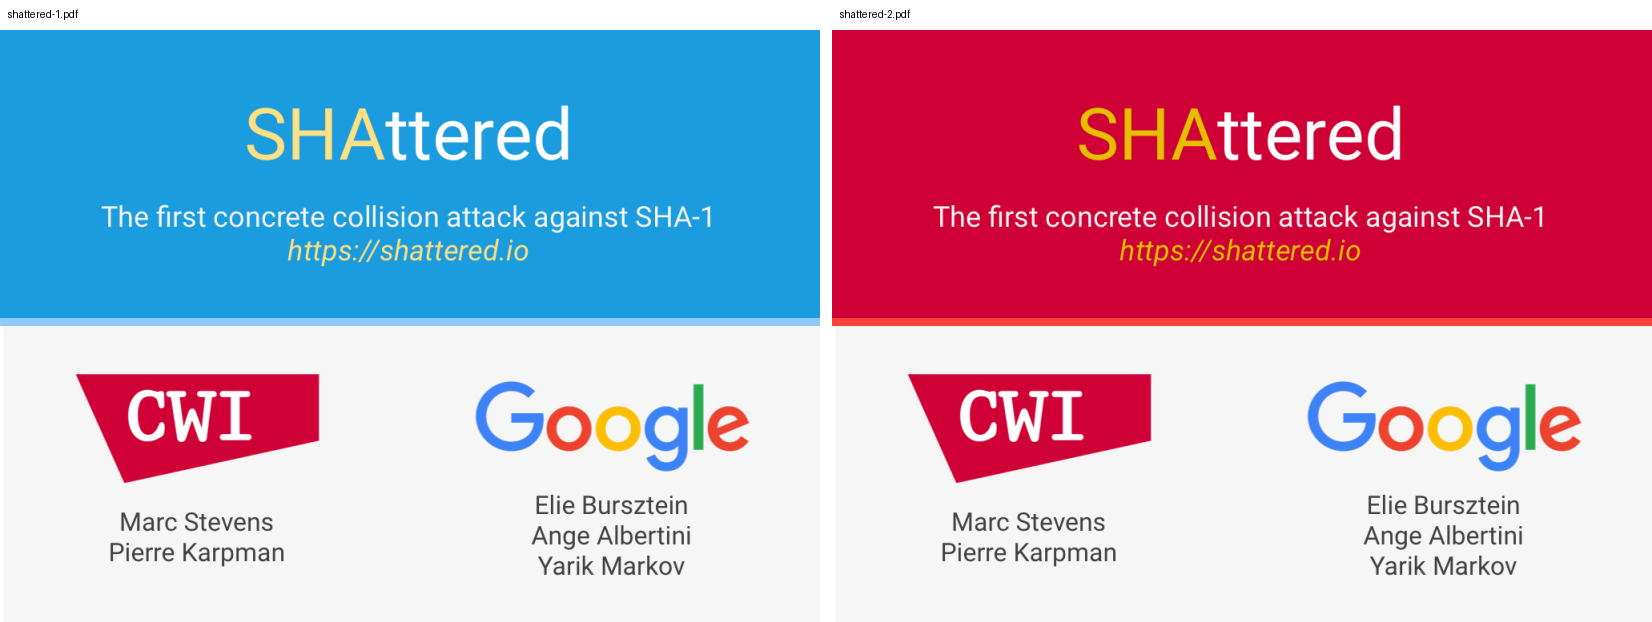

In [4]:
import pypdfium2 as pdfium
from IPython.display import display
from PIL import Image, ImageDraw

previews = []
for name in ('shattered-1.pdf', 'shattered-2.pdf'):
    with pdfium.PdfDocument(DATA_DIR / name) as document:
        previews.append(document[0].render(scale=0.8).to_pil().convert('RGB'))
width, height = previews[0].size
comparison = Image.new('RGB', (2 * width + 12, height + 30), 'white')
draw = ImageDraw.Draw(comparison)
for i, preview in enumerate(previews):
    draw.text((i * (width + 12) + 8, 8), f'shattered-{i + 1}.pdf', fill='black')
    comparison.paste(preview, (i * (width + 12), 30))
display(comparison)


In [5]:
pdf1, pdf2 = (DATA_DIR / f'shattered-{i}.pdf' for i in (1, 2))
first, second = pdf1.read_bytes(), pdf2.read_bytes()
print('Độ dài hai tệp:', len(first), 'và', len(second), 'byte')
print('Số byte khác biệt:', len(different_bytes(first, second)))
for name, path in [('shattered-1.pdf', pdf1), ('shattered-2.pdf', pdf2)]:
    print(name)
    print('SHA-1:  ', file_digest(path, 'sha1'))
    print('SHA-256:', file_digest(path, 'sha256'))
print('Dữ liệu khác nhau:', first != second)
print('SHA-1 trùng nhau:', file_digest(pdf1, 'sha1') == file_digest(pdf2, 'sha1'))
print('SHA-256 trùng nhau:', file_digest(pdf1, 'sha256') == file_digest(pdf2, 'sha256'))
assert first != second and len(first) == len(second) == 422435
assert file_digest(pdf1, 'sha1') == file_digest(pdf2, 'sha1') == '38762cf7f55934b34d179ae6a4c80cadccbb7f0a'
assert file_digest(pdf1, 'sha256') != file_digest(pdf2, 'sha256')


Độ dài hai tệp: 422435 và 422435 byte
Số byte khác biệt: 62
shattered-1.pdf
SHA-1:   38762cf7f55934b34d179ae6a4c80cadccbb7f0a
SHA-256: 2bb787a73e37352f92383abe7e2902936d1059ad9f1ba6daaa9c1e58ee6970d0
shattered-2.pdf
SHA-1:   38762cf7f55934b34d179ae6a4c80cadccbb7f0a
SHA-256: d4488775d29bdef7993367d541064dbdda50d383f89f0aa13a6ff2e0894ba5ff
Dữ liệu khác nhau: True
SHA-1 trùng nhau: True
SHA-256 trùng nhau: False


## 4 Kết luận
- Hai thông điệp khác 6 byte nhưng cùng MD5; hello/erase khác nội dung và hành vi
  nhưng cùng MD5. Hai PDF có hình hiển thị khác nhau nhưng cùng SHA-1.
- Hàm băm ánh xạ tập đầu vào không giới hạn vào đầu ra hữu hạn: MD5 128 bit,
  SHA-1 160 bit. Theo nguyên lý Dirichlet, va chạm tất yếu tồn tại. Yêu cầu bảo mật
  là việc **tìm** chúng phải không khả thi về tính toán.
- Các mẫu được tạo có chủ đích bằng phân tích sai khác, khai thác điểm yếu của hàm
  nén và sự lan truyền sai khác qua các vòng. Đây là bằng chứng tính kháng va chạm
  của MD5/SHA-1 bị phá vỡ, không phải việc đảo ngược một giá trị băm bất kỳ.
- Không dùng MD5/SHA-1 làm căn cứ bảo mật duy nhất để xác nhận tệp hay chữ ký số.
  SHA-256 phân biệt được cặp PDF này; khi cần xác thực nguồn gửi, cần MAC hoặc chữ
  ký số dùng thuật toán phù hợp, vì hash đơn thuần không chứng minh nguồn gốc.

## Tài liệu tham khảo
1. Đề Lab03, Nhiệm vụ 2.2, trang PDF 7–8.
2. Peter Selinger, MD5 Collision Demo: https://www.mscs.dal.ca/~selinger/md5collision/
3. Nhóm Google/CWI, Announcing the first SHA1 collision (23/02/2017):
   https://security.googleblog.com/2017/02/announcing-first-sha1-collision.html
4. Marc Stevens, dữ liệu SHAttered:
   https://github.com/cr-marcstevens/sha1collisiondetection/tree/a06f1adbe5522f3c939cd6a3f13d5ec7f4c1a988/test
